---
numbering: false
---

# Download Sentinel-2 Data

## Use `pystac-client` to search for Sentinel-2 data

In [20]:
import pystac_client
import planetary_computer
import odc.stac

import geopandas as gpd
import rioxarray as rxr

import matplotlib.pyplot as plt

from shapely import box

Set out our search criteria.

In [21]:
# Provide a name for our area of interest (AOI)
aoi_name = "bristol"

# Provide the bounding box coordinates for the AOI in the format [min_lon, min_lat, max_lon, max_lat]
bbox = [-2.76, 51.38,-2.43,51.53]

# Provide the date range for the search in the format "YYYY-MM-DD/YYYY-MM-DD"
daterange = "2026-06-01/2026-08-31"  # summer 2026

# Provide a cloud cover percentage threshold for filtering the search results
max_cloud_percent = 20  # maximum cloud cover percentage

# Provide a 'collection' from the Microsoft Planetary Computer STAC API to search for imagery. 
# For example, "sentinel-2-l2a" for Sentinel-2 Level 2A (Surface Reflectance) data.
# See https://planetarycomputer.microsoft.com/CATALOG for more examples
collection = "sentinel-2-l2a"

Turn our bbox list into a `GeoPandas` dataframe to sanity check we have the correct region:

In [4]:
aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

aoi.explore()

Connect the Microsoft Planetary Computer.

In [22]:
# Connect to the MPC
stac_url = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = pystac_client.Client.open(
    stac_url,
    modifier=planetary_computer.sign_inplace,  # only needed for MPC

    )

Search for the dataset according to our search parameters, sorted by cloud cover in ascending order.

In [23]:
# Search for cloud-free Sentinel-2 L2A imagery in Summer
search = catalog.search(
    collections=[collection],
    bbox=bbox,
    datetime=daterange,
    query={
        "eo:cloud_cover": {"lt": max_cloud_percent},  # Cloud cover less than 15%
        }, 
    sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}]  # Sort by cloud cover in ascending order
)

# Convert the search result object into a list of `pystac.Item` objects
items = search.item_collection()
print(f"Found {len(items)} matching scene(s).")

Found 30 matching scene(s).


## Downloading data with `odc-stac`

Select the first item (or edit the index number to select another if this one isn't suitable).

In [24]:
item = items[0]

date = item.properties['datetime'][:10]
epsg = item.properties['proj:code']
satellite = item.properties['platform']

print(f"Selected Scene ID: {item.id}")
print(f"Acquisition Date: {item.properties['datetime']}")
print(f"Cloud Cover: {item.properties['eo:cloud_cover']}%")
print(f"Projection: {item.properties['proj:code']}")

Selected Scene ID: S2C_MSIL2A_20260813T110621_R137_T30UWB_20260813T144414
Acquisition Date: 2026-08-13T11:06:21.025000Z
Cloud Cover: 0.613306%
Projection: EPSG:32630


Select the Sentinel-2 bands we want, and use `odc.stac.load()` to load our data. 

In [15]:
# Requested bands - I've commented out some we don't need for now, but you can uncomment them if you want to use them later
bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir',  # band 8, near-infrared
    # 'swir16',  # band 11, shortwave infrared 1
    # 'swir22',  # band 12, shortwave infrared 2
]

# Load requested bands directly into an xarray.Dataset using odc-stac
ds = odc.stac.load(
    [item],
    bands=bands,
    bbox=bbox,
    # crs="EPSG:XXXX",  # Uncomment if you want a different projection: by default, will use the native CRS
    # resolution=100, # Uncomment if you want a different resolution: by default, will use the native resolution of the imagery
).squeeze()

# xarray is 'lazy' by default, meaning it doesn't load the data into memory until you explicitly ask for it.
# The `.compute()` method forces the data to be loaded into memory, which can take some time depending on the size of the dataset.
ds.compute()

<xarray.Dataset> Size: 62MB
Dimensions:      (y: 1681, x: 2303)
Coordinates:
  * y            (y) float64 13kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 18kB 5.166e+05 5.167e+05 ... 5.397e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-08-13T11:06:21.025000
Data variables:
    blue         (y, x) float32 15MB nan nan nan ... 1.812e+03 2.072e+03
    green        (y, x) float32 15MB nan nan nan ... 2.249e+03 2.516e+03
    red          (y, x) float32 15MB nan nan nan ... 2.818e+03 3.289e+03
    nir          (y, x) float32 15MB nan nan nan ... 4.906e+03 4.924e+03

Convert to a `band` dimension and add appropriate attribute names. Also, convert to surface refelctance.

In [16]:
# stack variables into a band dimension
ds = ds.to_array(dim="band").squeeze()

# add the band names as a long_name attribute to the dataset
ds.attrs["long_name"] = list(ds["band"].values)


# Surface reflectance scaling for sentinel-2
ds = ds / 10000.0

# Visualise
ds

<xarray.DataArray (band: 4, y: 1681, x: 2303)> Size: 62MB
array([[[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1478, 0.1464, 0.1483, ..., 0.1782, 0.1876, 0.1983],
        [0.1449, 0.1473, 0.1487, ..., 0.1785, 0.178 , 0.2014],
        [0.1491, 0.1509, 0.1488, ..., 0.1768, 0.1812, 0.2072]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1748, 0.174 , 0.1764, ..., 0.2098, 0.2332, 0.2436],
        [0.177 , 0.1782, 0.1778, ..., 0.2113, 0.2206, 0.2469],
        [0.1778, 0.1778, 0.1754, ..., 0.2151, 0.2249, 0.2516]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1704, 0.1682, 0.1711, ..., 0.2561, 0.286 , 0.3164],
        [0.1657, 0.1671, 0.1699, ..., 0.2503, 0.2718, 0.3207],
        [0.1665, 0.1721, 0.1728, ..., 0.2455, 0.2818, 0.3289]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.413 , 0.4206, 0.4184, ..., 0.4337, 0.4667, 0.4909],
        [0.444 , 0.443 , 0.4306, ..., 0.4271, 0.4757, 0.4891],
        [0.446 , 0.432 , 0.4223, ..., 0.4298, 0.4906, 0.4924]]],
      shape=(4, 1681, 2303), dtype=float32)
Coordinates:
  * band         (band) object 32B 'blue' 'green' 'red' 'nir'
  * y            (y) float64 13kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 18kB 5.166e+05 5.167e+05 ... 5.397e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-08-13T11:06:21.025000
Attributes:
    long_name:  ['blue', 'green', 'red', 'nir']

Visualise to check the image has good coverage and quality. If it isn't appropriate, you can explore a different `item` above (e.g. `item = items[3]`).

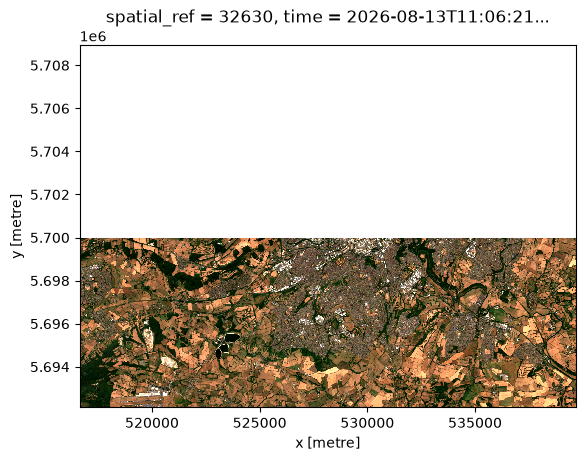

In [17]:
rgb = ds.sel(band=["red", "green", "blue"])

fig, ax = plt.subplots()
rgb.plot.imshow(ax=ax, robust=True)
ax.set_aspect("equal")

> This is a good example of a not-perfect satellite image: it has been cut in half over the AOI. You have a couple options here:
>  - You could carry on searching different images until you find an image that covers the AOI.
>  - You could limit the search to the one day this image was taken, and either (i) download each image individually and merge them using `rioxarray` functions; or (ii) provide multiple `items` to the `odc.stac.load()` function, and use `xarray` to merge/combine the image along the `time` dimension.
> This first is a bit easier if you don't care too much about the day!

Save this under a sensible name, auto-generated from parameters:

In [18]:
filename = f"{aoi_name}_{date}_{satellite}.tif"

print('Saving to:', filename)

ds.rio.to_raster(filename, driver="GTiff", compress="deflate")

Saving to: bristol_2026-08-13_Sentinel-2C.tif


An example of how to load the data:

In [19]:
ds_loaded = rxr.open_rasterio(filename, masked=True).squeeze()

ds_loaded['band'] = list(ds_loaded.attrs["long_name"])

ds_loaded

<xarray.DataArray (band: 4, y: 1681, x: 2303)> Size: 62MB
array([[[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1478, 0.1464, 0.1483, ..., 0.1782, 0.1876, 0.1983],
        [0.1449, 0.1473, 0.1487, ..., 0.1785, 0.178 , 0.2014],
        [0.1491, 0.1509, 0.1488, ..., 0.1768, 0.1812, 0.2072]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1748, 0.174 , 0.1764, ..., 0.2098, 0.2332, 0.2436],
        [0.177 , 0.1782, 0.1778, ..., 0.2113, 0.2206, 0.2469],
        [0.1778, 0.1778, 0.1754, ..., 0.2151, 0.2249, 0.2516]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.1704, 0.1682, 0.1711, ..., 0.2561, 0.286 , 0.3164],
        [0.1657, 0.1671, 0.1699, ..., 0.2503, 0.2718, 0.3207],
        [0.1665, 0.1721, 0.1728, ..., 0.2455, 0.2818, 0.3289]],

       [[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [0.413 , 0.4206, 0.4184, ..., 0.4337, 0.4667, 0.4909],
        [0.444 , 0.443 , 0.4306, ..., 0.4271, 0.4757, 0.4891],
        [0.446 , 0.432 , 0.4223, ..., 0.4298, 0.4906, 0.4924]]],
      shape=(4, 1681, 2303), dtype=float32)
Coordinates:
  * band         (band) object 32B 'blue' 'green' 'red' 'nir'
  * y            (y) float64 13kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 18kB 5.166e+05 5.167e+05 ... 5.397e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-08-13T11:06:21.025000
Attributes:
    long_name:  ['blue', 'green', 'red', 'nir']